# Entraînement du MLP Walter

Ce notebook ne contient que la configuration et l'orchestration. Le chargement des données, le modèle, la validation croisée, l'arrêt anticipé et les checkpoints sont implémentés dans `src/py`.

In [39]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import torch

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents) if (path / 'src' / 'py' / 'fpga_targets.py').is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError('Impossible de trouver la racine du projet.')

source_dir = PROJECT_ROOT / 'src' / 'py'
if str(source_dir) not in sys.path:
    sys.path.insert(0, str(source_dir))

from training import (
    angular_error_deg,
    load_trained_model,
    load_training_dataset,
    save_training_result,
    train_cross_validated,
    validate_training_config,
)

## Configuration unique

`target_unit` indique l'unité du tableau `pos` dans le fichier NPZ. Le modèle prédit toujours des radians; l'erreur affichée est toujours en degrés.

In [ ]:
config = {
    'dataset_name': 'fashion_mnist.npz',
    'dataset_path': 'data/fashion_mnist.npz',
    'input_dim': 784,
    'output_dim': 10,
    'layers': (64, 32),
    'activation': 'leaky_relu',
    'optimizer': 'AdamW',
    'init_weight': 'glorot_uniform',
    'learning_rate': 1e-3,
    'batch_size': 64,
    'epochs': 100,
    'patience': 20,
    'nb_splits': 5,
    'shuffle': True,
    'random_state': 7,
    'save_dir': 'data/fashion_mnist',
    'name': 'mlp_fashion_mnist.pt',
}

config = validate_training_config(config)
config

{'dataset_name': 'fashion_mnist.npz',
 'dataset_path': 'data/fashion_mnist.npz',
 'input_dim': 784,
 'output_dim': 10,
 'layers': (64, 32),
 'activation': 'leaky_relu',
 'optimizer': 'AdamW',
 'init_weight': 'glorot_uniform',
 'learning_rate': 0.001,
 'batch_size': 64,
 'epochs': 100,
 'patience': 20,
 'nb_splits': 5,
 'shuffle': True,
 'random_state': 7,
 'save_dir': 'data/fashion_mnist',
 'name': 'mlp_fashion_mnist.pt'}

## Chargement et validation des données

In [41]:
dataset = load_training_dataset(config, project_root=PROJECT_ROOT)

print(f'Dataset : {dataset.path}')
print(f'Entrées : {dataset.x.shape} {dataset.x.dtype}')
print(f'Labels : {dataset.y.shape} {dataset.y.dtype}')

Dataset : C:\Users\adams\Documents\MLP_HLS-main\data\fashion_mnist.npz
Entrées : (60000, 784) float32
Labels : (60000,) int64


## Validation croisée et entraînement

In [42]:
result = train_cross_validated(config, project_root=PROJECT_ROOT)
scores_df = pd.DataFrame(result.fold_scores)
scores_df

Fold 1/5:   0%|          | 0/100 [00:00<?, ?it/s]

Fold 1: early stopping at epoch 60 (best accuracy=89.58%)


Fold 2/5:   0%|          | 0/100 [00:00<?, ?it/s]

Fold 2: early stopping at epoch 57 (best accuracy=89.37%)


Fold 3/5:   0%|          | 0/100 [00:00<?, ?it/s]

Fold 3: early stopping at epoch 50 (best accuracy=89.56%)


Fold 4/5:   0%|          | 0/100 [00:00<?, ?it/s]

Fold 4: early stopping at epoch 66 (best accuracy=89.06%)


Fold 5/5:   0%|          | 0/100 [00:00<?, ?it/s]

Fold 5: early stopping at epoch 53 (best accuracy=89.00%)


,fold,best_val_accuracy
0,1,0.895750
1,2,0.893667
2,3,0.895583
3,4,0.890583
4,5,0.890000


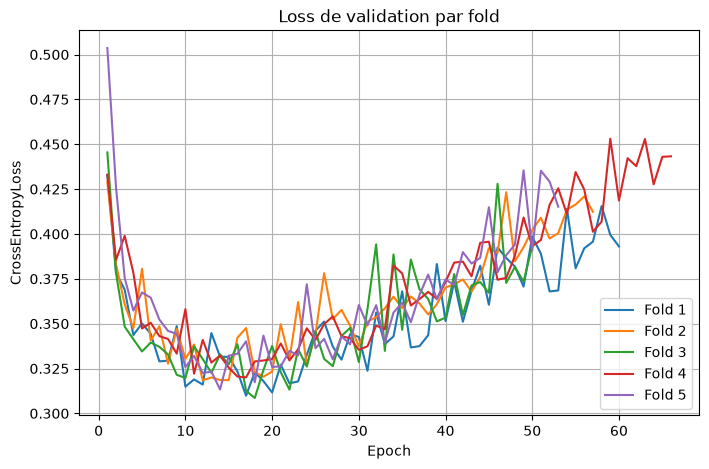

In [43]:
history_df = pd.DataFrame(result.history_rows)

fig, ax = plt.subplots(figsize=(8, 5))

for fold, history in history_df.groupby('fold'):
    ax.plot(
        history['epoch'],
        history['val_loss'],
        label=f'Fold {fold}'
    )

ax.set(
    xlabel='Epoch',
    ylabel='CrossEntropyLoss',
    title='Loss de validation par fold',
)

ax.grid(True)
ax.legend()
plt.show()

## Sauvegarde du meilleur modèle

Le format reste compatible avec la suite du pipeline : `model_state_dict`, `config`, `best_global_fold` et `best_global_val` sont conservés.

In [44]:
model_path = save_training_result(result, project_root=PROJECT_ROOT)

print(f'Modèle sauvegardé : {model_path}')
print(f'Meilleur fold : {result.best_fold}')
print(f'Meilleure validation : {result.best_val_accuracy:.2%}')

Modèle sauvegardé : C:\Users\adams\Documents\MLP_HLS-main\data\fashion_mnist\mlp_fashion_mnist.pt
Meilleur fold : 1
Meilleure validation : 89.58%


## Vérification rapide du checkpoint

In [45]:

# Recharger le modèle entraîné
model, checkpoint = load_trained_model(
    model_path, device=result.device
)

model.eval()

# Tester sur 10 images
with torch.no_grad():
    x_test = torch.from_numpy(dataset.x[:10]).to(result.device)
    y_test = torch.from_numpy(dataset.y[:10]).to(result.device)

    # Prédictions du réseau (logits)
    logits = model(x_test)

    # Classe prédite
    predictions = logits.argmax(dim=1)

    # Accuracy sur les 10 images
    accuracy = (predictions == y_test).float().mean()

print("Classes réelles :")
print(y_test.cpu().numpy())

print("Classes prédites :")
print(predictions.cpu().numpy())

print(f"Accuracy sur les 10 images : {accuracy.item():.2%}")


Classes réelles :
[9 0 0 3 0 2 7 2 5 5]
Classes prédites :
[9 0 0 3 3 2 7 4 5 5]
Accuracy sur les 10 images : 80.00%
